# VITT Financial Analysis

Analyze 3,000 fictional Indian customers. All money values are in INR. The models are for learning, not validated investment advice.

## A. Load the data

Read the saved CSV and check the columns, missing values, and duplicates.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Run this notebook from the Vitt-Financial-Analytics folder.
project_root = Path.cwd()
if not (project_root / 'data/synthetic_customers.csv').exists():
    project_root = project_root / 'Vitt-Financial-Analytics'
raw_path = project_root / 'data/synthetic_customers.csv'
graphs_path = project_root / 'graphs'
graphs_path.mkdir(exist_ok=True)
raw_hash = hashlib.sha256(raw_path.read_bytes()).hexdigest()

customers = pd.read_csv(raw_path)
display(customers.head())
print('Shape:', customers.shape)

customers.info()

display(customers.describe(include='all').T)
display(customers.isna().sum().rename('Missing values'))
print('Duplicate rows:', customers.duplicated().sum())
print('Duplicate IDs:', customers.customer_id.duplicated().sum())

,customer_id,age,region_segment,employment_type,income_stability,dependents,monthly_income,essential_expenses,discretionary_expenses,monthly_emi,outstanding_debt,liquid_savings,invested_assets,investment_horizon,risk_preference,financial_goal,financial_confidence_score
0,VITT00001,54,Semi-Urban,Salaried,Variable,0,12484.0,2520.0,1593.0,6005.0,762261.0,65427.0,58202.0,5,Aggressive,Emergency Savings,43
1,VITT00002,56,Semi-Urban,Salaried,Moderate,0,164005.0,83349.0,28260.0,68226.0,7804430.0,456252.0,10245608.0,19,Moderate,Retirement,20
2,VITT00003,39,Semi-Urban,Self-Employed,Stable,3,50374.0,23528.0,10261.0,17115.0,1409444.0,238617.0,283523.0,12,Conservative,Education,48
3,VITT00004,60,Urban,Salaried,Stable,2,117303.0,51023.0,16795.0,42458.0,904831.0,266306.0,164664.0,4,Conservative,Education,64
4,VITT00005,56,Urban,Salaried,Moderate,5,127302.0,82840.0,22321.0,0.0,0.0,504192.0,1986245.0,9,Moderate,Home Purchase,72


Shape: (3000, 17)
<class 'pandas.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   customer_id                 3000 non-null   str    
 1   age                         3000 non-null   int64  
 2   region_segment              3000 non-null   str    
 3   employment_type             3000 non-null   str    
 4   income_stability            3000 non-null   str    
 5   dependents                  3000 non-null   int64  
 6   monthly_income              3000 non-null   float64
 7   essential_expenses          3000 non-null   float64
 8   discretionary_expenses      3000 non-null   float64
 9   monthly_emi                 3000 non-null   float64
 10  outstanding_debt            3000 non-null   float64
 11  liquid_savings              3000 non-null   float64
 12  invested_assets             3000 non-null   float64
 13  investment_horizon        

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,3000,3000,VITT00001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,3000.0,NaN,NaN,NaN,43.176333,12.898502,21.0,32.0,43.0,54.0,65.0
region_segment,3000,3,Urban,1419,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_type,3000,4,Salaried,1487,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_stability,3000,3,Stable,1316,NaN,NaN,NaN,NaN,NaN,NaN,NaN
dependents,3000.0,NaN,NaN,NaN,1.879,1.33077,0.0,1.0,2.0,3.0,5.0
monthly_income,3000.0,NaN,NaN,NaN,63309.368333,45042.673044,10000.0,33422.75,52217.0,79153.75,400000.0
essential_expenses,3000.0,NaN,NaN,NaN,28685.511667,22695.574807,2431.0,13550.0,22431.5,36220.0,215006.0
discretionary_expenses,3000.0,NaN,NaN,NaN,9514.814,8441.083709,453.0,4084.25,7193.5,11874.0,94854.0
monthly_emi,3000.0,NaN,NaN,NaN,12037.041333,15586.002507,0.0,0.0,7704.5,17318.75,190585.0


customer_id                   0
age                           0
region_segment                0
employment_type               0
income_stability              0
dependents                    0
monthly_income                0
essential_expenses            0
discretionary_expenses        0
monthly_emi                   0
outstanding_debt              0
liquid_savings                0
invested_assets               0
investment_horizon            0
risk_preference               0
financial_goal                0
financial_confidence_score    0
Name: Missing values, dtype: int64

Duplicate rows: 0
Duplicate IDs: 0


In [2]:
expected_columns = ['customer_id', 'age', 'region_segment', 'employment_type',
    'income_stability', 'dependents', 'monthly_income', 'essential_expenses',
    'discretionary_expenses', 'monthly_emi', 'outstanding_debt', 'liquid_savings',
    'invested_assets', 'investment_horizon', 'risk_preference', 'financial_goal',
    'financial_confidence_score']
assert customers.shape == (3000, 17)
assert customers.columns.tolist() == expected_columns
assert customers.customer_id.is_unique and not customers.isna().any().any()
assert customers.age.between(18, 90).all()
assert (customers.monthly_income > 0).all()
assert (customers.select_dtypes('number') >= 0).all().all()
assert np.isfinite(customers.select_dtypes('number')).all().all()
assert customers.financial_confidence_score.between(0, 100).all()
assert ((customers.monthly_emi == 0) == (customers.outstanding_debt == 0)).all()
allowed_labels = {
    'region_segment': ['Urban', 'Semi-Urban', 'Rural'],
    'employment_type': ['Salaried', 'Self-Employed', 'Farmer', 'Other'],
    'income_stability': ['Stable', 'Moderate', 'Variable'],
    'risk_preference': ['Conservative', 'Moderate', 'Aggressive'],
    'financial_goal': ['Wealth Creation', 'Retirement', 'Education', 'Home Purchase', 'Emergency Savings']}
for column, labels in allowed_labels.items():
    assert customers[column].isin(labels).all()
print('Input checks passed. No cleaning or imputation needed.')

Input checks passed. No cleaning or imputation needed.


## B. Financial metrics - definitions and formulas

Total monthly expenses: Money spent on essential and discretionary expenses.

Total monthly expenses = Essential expenses + Discretionary expenses

Monthly surplus: Money left after expenses and EMI.

Monthly surplus = Monthly income - Total monthly expenses - Monthly EMI

Savings rate: Percentage of income that could be saved, not actual savings.

Savings rate (%) = Monthly surplus / Monthly income * 100

Debt-to-income ratio: Percentage of take-home income used for EMI.

DTI (%) = Monthly EMI / Monthly income * 100

Emergency coverage: Number of months liquid savings can cover essential expenses and EMI.

Emergency coverage (months) = Liquid savings / (Essential expenses + Monthly EMI)

Financial vulnerability: A customer meets at least one of the following project conditions.

Financially vulnerable = Emergency coverage < 3 OR DTI >= 40 OR Monthly surplus <= 0

DTI uses take-home income instead of gross income. Zero coverage denominators return missing values; none occur in this dataset. The original confidence score stays unchanged.

In [3]:
def calculate_financial_metrics(data):
    result = data.copy()
    result['total_monthly_expenses'] = result.essential_expenses + result.discretionary_expenses
    result['monthly_surplus'] = result.monthly_income - result.total_monthly_expenses - result.monthly_emi
    result['savings_rate_pct'] = result.monthly_surplus / result.monthly_income * 100
    result['dti_pct'] = result.monthly_emi / result.monthly_income * 100
    obligations = result.essential_expenses + result.monthly_emi
    result['emergency_coverage_months'] = result.liquid_savings / obligations.replace(0, np.nan)
    result['financially_vulnerable'] = ((result.emergency_coverage_months < 3)
        | (result.dti_pct >= 40) | (result.monthly_surplus <= 0))
    return result

baseline = calculate_financial_metrics(customers)
display(baseline[['customer_id', 'monthly_surplus', 'savings_rate_pct', 'dti_pct',
                  'emergency_coverage_months', 'financially_vulnerable']].head())

,customer_id,monthly_surplus,savings_rate_pct,dti_pct,emergency_coverage_months,financially_vulnerable
0,VITT00001,2366.0,18.952259,48.101570,7.674721,True
1,VITT00002,-15830.0,-9.652145,41.599951,3.010074,True
2,VITT00003,-530.0,-1.052130,33.975861,5.871048,True
3,VITT00004,7027.0,5.990469,36.195153,2.848771,True
4,VITT00005,22141.0,17.392500,0.000000,6.086335,False


## C. Risk Band

Risk Band shows investment risk-taking capacity and preference. It does not predict loan default.

Preference score = 0.15 for Conservative, 0.50 for Moderate, or 0.90 for Aggressive

Confidence score = Financial confidence score / 100

Horizon score = Investment horizon / 15, with a maximum of 1

Emergency score = Emergency coverage / 6, with a maximum of 1

Debt score = 1 - (DTI percentage / 50), with a minimum of 0

Risk Score = 0.40 * Preference score + 0.20 * Confidence score + 0.15 * Horizon score + 0.15 * Emergency score + 0.10 * Debt score

Risk Band = 1 + round(9 * Risk Score)

The weights are project assumptions and have not been validated. NumPy rounds halfway values to the nearest even number. The tests change one factor at a time.

In [4]:
def calculate_risk_band(data):
    result = data.copy()
    result['preference_score'] = result.risk_preference.map({'Conservative': .15, 'Moderate': .50, 'Aggressive': .90})
    result['confidence_score_normalized'] = result.financial_confidence_score / 100
    result['horizon_score'] = (result.investment_horizon / 15).clip(0, 1)
    # For an undefined coverage denominator, assign no emergency capacity credit.
    result['emergency_score'] = (result.emergency_coverage_months / 6).fillna(0).clip(0, 1)
    result['debt_score'] = (1 - result.dti_pct / 50).clip(0, 1)
    result['risk_score'] = (.40 * result.preference_score + .20 * result.confidence_score_normalized
        + .15 * result.horizon_score + .15 * result.emergency_score + .10 * result.debt_score)
    result['risk_band'] = (1 + np.round(9 * result.risk_score)).clip(1, 10).astype(int)
    return result

baseline = calculate_risk_band(baseline)
# Hold other scoring inputs fixed and change one factor at a time.
probe = pd.concat([baseline.iloc[[0]]] * 6, ignore_index=True)
probe['dti_pct'] = [0, 10, 20, 40, 50, 70]
probe['emergency_coverage_months'] = 4
debt_test = calculate_risk_band(probe)
assert (np.diff(debt_test.risk_score) <= 0).all()
assert (np.diff(debt_test.risk_band) <= 0).all()
probe['dti_pct'] = 20
probe['emergency_coverage_months'] = [0, 1, 3, 6, 9, 12]
emergency_test = calculate_risk_band(probe)
assert (np.diff(emergency_test.risk_score) >= 0).all()
assert (np.diff(emergency_test.risk_band) >= 0).all()
assert baseline.risk_band.between(1, 10).all()
print('Risk scoring monotonicity checks passed.')

Risk scoring monotonicity checks passed.


## D. Asset allocation and emergency reserve

Use the given Vitt allocation dictionary. Each customer's allocation must total 100%.

Safety includes FD, Liquid Funds, and Gold. Income includes Bonds and Corporate Debt. Growth includes Mutual Funds and Index Funds. Aggressive includes Direct Equity and Small-Cap Equity. Safety does not mean risk-free.

Emergency reserve target: The target amount of liquid savings.

Emergency reserve target = Target months * (Essential expenses + Monthly EMI)

Target months = 9 for bands 1 to 4, 6 for bands 5 to 7, and 3 for bands 8 to 10

Reserve shortfall: Extra savings needed to reach the target.

Reserve shortfall = Emergency reserve target - Liquid savings, with a minimum of 0

Positive monthly surplus = Monthly surplus, with a minimum of 0

Monthly reserve contribution: Money added to the reserve before investing.

Monthly reserve contribution = The smaller of positive monthly surplus and reserve shortfall

Potential investable surplus: Money left after the reserve contribution.

Potential investable surplus = Positive monthly surplus - Monthly reserve contribution

Allocations and reserve targets are simple project assumptions, not financial recommendations.

In [5]:
allocation_table = {
    1: [60, 30, 10, 0], 2: [50, 35, 15, 0], 3: [40, 35, 20, 5],
    4: [30, 35, 25, 10], 5: [20, 30, 35, 15], 6: [10, 25, 45, 20],
    7: [5, 15, 50, 30], 8: [0, 10, 45, 45], 9: [0, 5, 40, 55], 10: [0, 0, 30, 70]}
allocation_columns = ['safety_pct', 'income_pct', 'growth_pct', 'aggressive_pct']
for index, column in enumerate(allocation_columns):
    baseline[column] = baseline.risk_band.map({band: values[index] for band, values in allocation_table.items()})
assert (baseline[allocation_columns].sum(axis=1) == 100).all()
baseline['reserve_target_months'] = np.select([baseline.risk_band <= 4, baseline.risk_band <= 7], [9, 6], default=3)
baseline['emergency_reserve_target'] = baseline.reserve_target_months * (baseline.essential_expenses + baseline.monthly_emi)
baseline['emergency_reserve_shortfall'] = (baseline.emergency_reserve_target - baseline.liquid_savings).clip(lower=0)
baseline['monthly_reserve_contribution'] = np.minimum(baseline.monthly_surplus.clip(lower=0), baseline.emergency_reserve_shortfall)
baseline['potential_investable_surplus'] = baseline.monthly_surplus.clip(lower=0) - baseline.monthly_reserve_contribution
display(baseline[['risk_band'] + allocation_columns + ['emergency_reserve_target', 'potential_investable_surplus']].head())

,risk_band,safety_pct,income_pct,growth_pct,aggressive_pct,emergency_reserve_target,potential_investable_surplus
0,7,5,15,50,30,51150.0,2366.0
1,5,20,30,35,15,909450.0,0.0
2,5,20,30,35,15,243858.0,0.0
3,4,30,35,25,10,841329.0,0.0
4,7,5,15,50,30,497040.0,22141.0


## E. Explore the data

Create charts and describe the results. Blue is the main color. Amber highlights vulnerability. Findings apply only to this synthetic data.

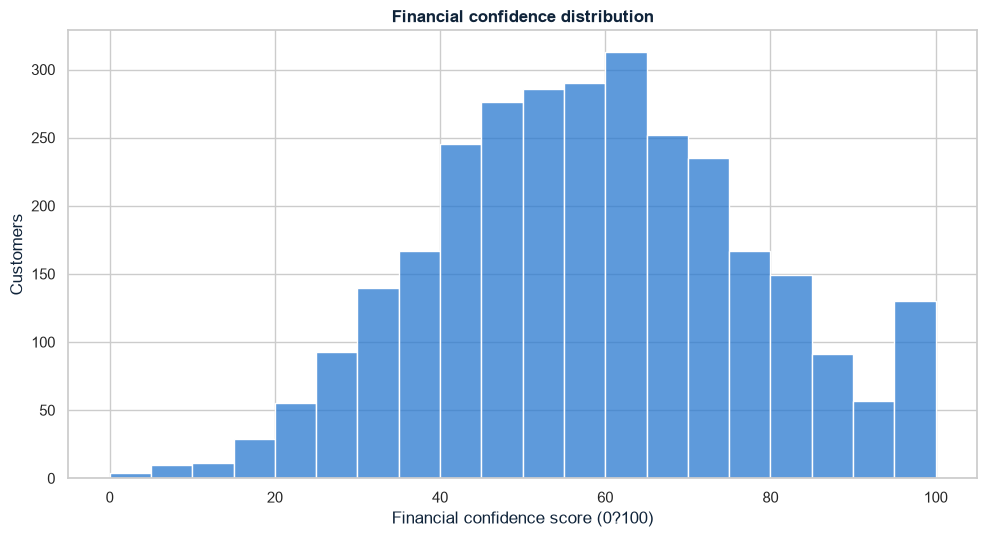

In [6]:
sns.set_theme(style='whitegrid', context='notebook')
blue = '#2878D0'
navy = '#10243A'
amber = '#E8AF50'
plt.rcParams.update({'figure.figsize': (10, 5.5), 'axes.titleweight': 'bold',
                     'axes.labelcolor': navy, 'text.color': navy, 'font.size': 11})

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(graphs_path / filename, dpi=300, bbox_inches='tight', facecolor='white')
    plt.show()
    plt.close()

sns.histplot(baseline.financial_confidence_score, bins=np.arange(0, 105, 5), color=blue)
plt.title('Financial confidence distribution')
plt.xlabel('Financial confidence score (0?100)')
plt.ylabel('Customers')
save_chart('confidence_distribution.png')

In [7]:
display(Markdown(f"**Interpretation:** Mean confidence is {baseline.financial_confidence_score.mean():.1f} and median is {baseline.financial_confidence_score.median():.1f}. The middle 50% spans {baseline.financial_confidence_score.quantile(.25):.0f}?{baseline.financial_confidence_score.quantile(.75):.0f}. Scores are synthetic inputs, not a validated survey."))

**Interpretation:** Mean confidence is 58.0 and median is 58.0. The middle 50% spans 44?71. Scores are synthetic inputs, not a validated survey.

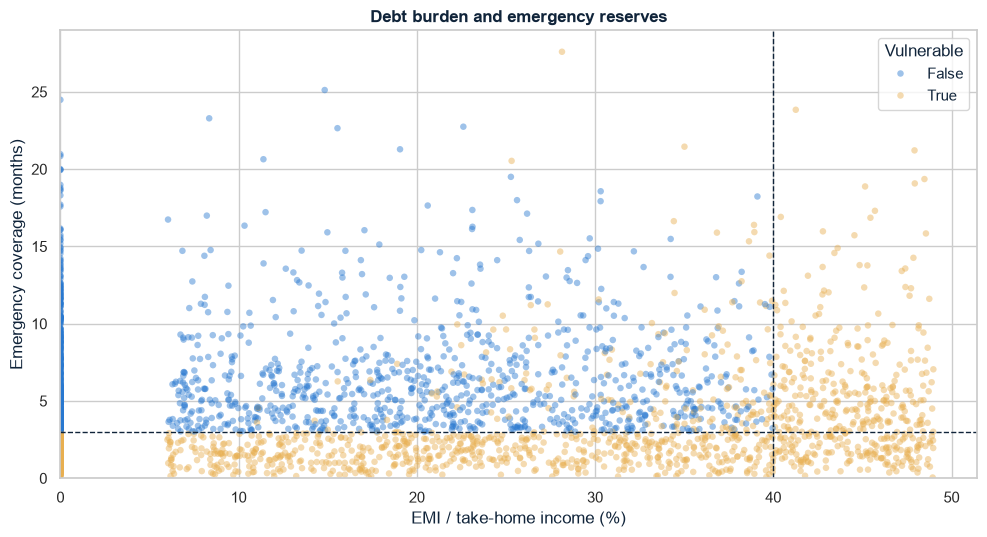

In [8]:
sns.scatterplot(data=baseline, x='dti_pct', y='emergency_coverage_months', hue='financially_vulnerable',
                palette={False: blue, True: amber}, alpha=.45, s=22, linewidth=0)
plt.axvline(40, color=navy, linestyle='--', linewidth=1)
plt.axhline(3, color=navy, linestyle='--', linewidth=1)
plt.xlim(left=0)
plt.ylim(bottom=0)
plt.title('Debt burden and emergency reserves')
plt.xlabel('EMI / take-home income (%)')
plt.ylabel('Emergency coverage (months)')
plt.legend(title='Vulnerable')
save_chart('debt_vs_emergency.png')

In [9]:
display(Markdown(f"**Interpretation:** {(baseline.dti_pct >= 40).mean()*100:.1f}% have DTI at least 40%, and {(baseline.emergency_coverage_months < 3).mean()*100:.1f}% have coverage below 3 months. Maximum coverage is {baseline.emergency_coverage_months.max():.1f} months; all points are included. Vulnerability also includes nonpositive surplus, so some amber points lie outside the two marked threshold areas."))

**Interpretation:** 14.3% have DTI at least 40%, and 38.0% have coverage below 3 months. Maximum coverage is 27.6 months; all points are included. Vulnerability also includes nonpositive surplus, so some amber points lie outside the two marked threshold areas.

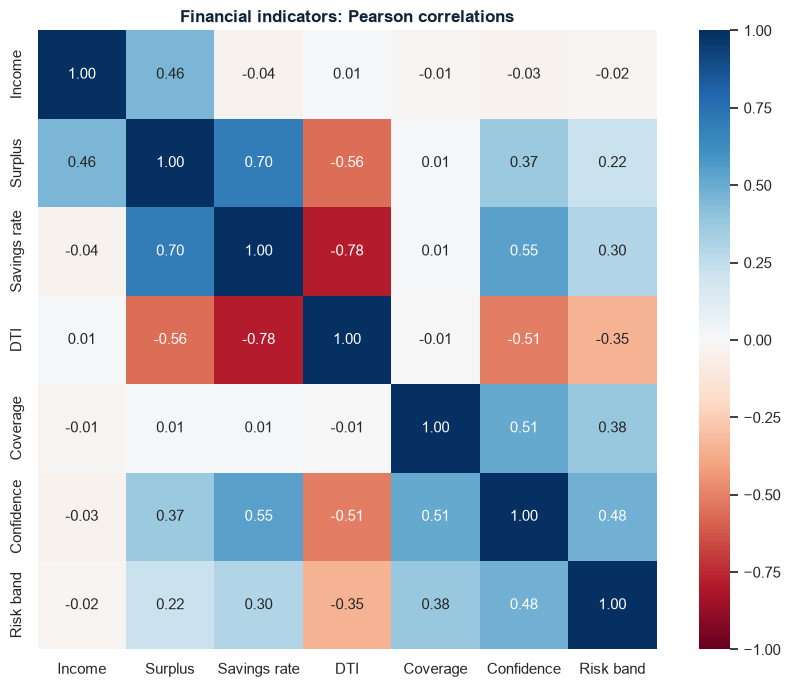

In [10]:
correlation_columns = ['monthly_income', 'monthly_surplus', 'savings_rate_pct', 'dti_pct',
                       'emergency_coverage_months', 'financial_confidence_score', 'risk_band']
labels = ['Income', 'Surplus', 'Savings rate', 'DTI', 'Coverage', 'Confidence', 'Risk band']
correlations = baseline[correlation_columns].corr()
plt.figure(figsize=(9, 7))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-1, vmax=1,
            xticklabels=labels, yticklabels=labels, square=True)
plt.title('Financial indicators: Pearson correlations')
save_chart('correlation_heatmap.png')

In [11]:
display(Markdown(f"**Interpretation:** Savings rate and DTI correlate at {correlations.loc['savings_rate_pct','dti_pct']:.2f}; EMI directly reduces surplus and both ratios share income as a denominator. Confidence and coverage correlate at {correlations.loc['financial_confidence_score','emergency_coverage_months']:.2f}, partly because confidence was constructed from synthetic circumstances. Confidence and Risk Band correlate at {correlations.loc['financial_confidence_score','risk_band']:.2f}; confidence is an explicit scoring input. These are not independent validation results."))

**Interpretation:** Savings rate and DTI correlate at -0.78; EMI directly reduces surplus and both ratios share income as a denominator. Confidence and coverage correlate at 0.51, partly because confidence was constructed from synthetic circumstances. Confidence and Risk Band correlate at 0.48; confidence is an explicit scoring input. These are not independent validation results.

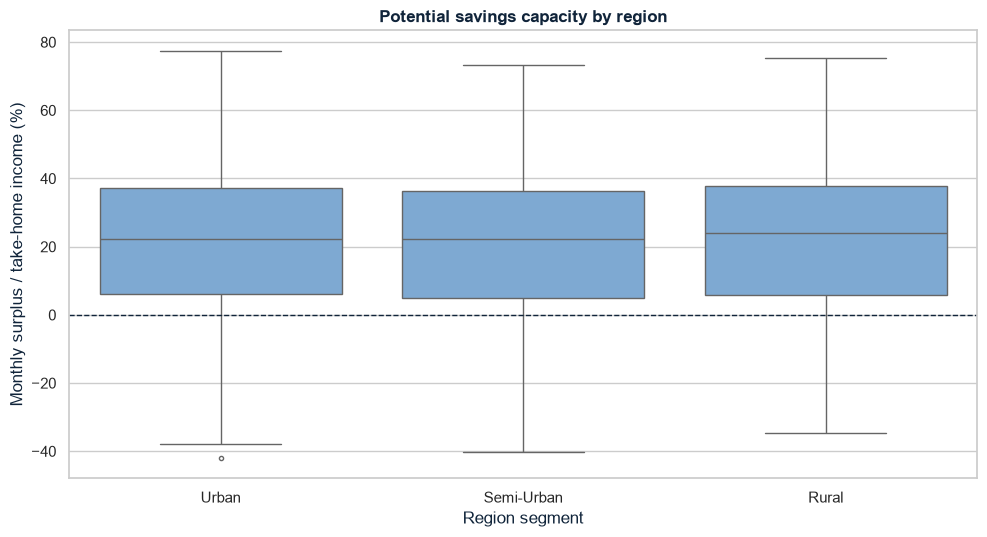

In [12]:
region_order = ['Urban', 'Semi-Urban', 'Rural']
sns.boxplot(data=baseline, x='region_segment', y='savings_rate_pct', order=region_order,
            color='#70A9E0', fliersize=3)
plt.axhline(0, color=navy, linestyle='--', linewidth=1)
plt.title('Potential savings capacity by region')
plt.xlabel('Region segment')
plt.ylabel('Monthly surplus / take-home income (%)')
save_chart('savings_by_region.png')

In [13]:
region_medians = baseline.groupby('region_segment').savings_rate_pct.median().reindex(region_order)
display(Markdown('**Interpretation:** Median savings rates: ' + ', '.join(f'{region} {value:.1f}%' for region, value in region_medians.items()) + '. Boxes show the middle 50%; points beyond 1.5 times the interquartile range are displayed rather than removed. Regional differences describe this simulated sample only.'))

**Interpretation:** Median savings rates: Urban 22.1%, Semi-Urban 22.2%, Rural 23.9%. Boxes show the middle 50%; points beyond 1.5 times the interquartile range are displayed rather than removed. Regional differences describe this simulated sample only.

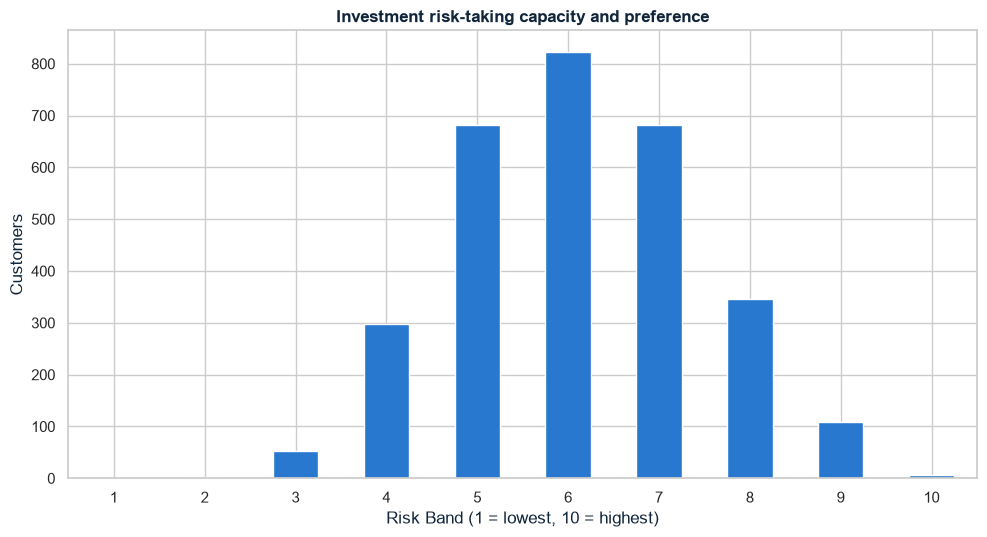

In [14]:
risk_counts = baseline.risk_band.value_counts().reindex(range(1, 11), fill_value=0)
risk_counts.plot.bar(color=blue, rot=0)
plt.title('Investment risk-taking capacity and preference')
plt.xlabel('Risk Band (1 = lowest, 10 = highest)')
plt.ylabel('Customers')
save_chart('risk_distribution.png')

In [15]:
display(Markdown(f"**Interpretation:** Band {risk_counts.idxmax()} is most common ({risk_counts.max():,} customers). Observed bands range from {baseline.risk_band.min()} to {baseline.risk_band.max()}. Empty bands remain visible; the scoring inputs do not need to populate every band. Higher bands do not mean higher loan-default probability."))

**Interpretation:** Band 6 is most common (823 customers). Observed bands range from 2 to 10. Empty bands remain visible; the scoring inputs do not need to populate every band. Higher bands do not mean higher loan-default probability.

## F. Stress testing

Start each scenario with a fresh copy of the original data. Change income or essential expenses and calculate the metrics and Risk Band again.

Keep confidence, EMI, other spending, assets, horizon, and preference unchanged. Income-only changes leave emergency coverage unchanged.

These are monthly snapshots. They do not model savings running out or changes in customer behavior. Allocations and reserve targets remain baseline examples.

In [16]:
scenarios = {
    'Baseline': (1.00, 1.00),
    'Income reduction 10%': (.90, 1.00),
    'Income reduction 20%': (.80, 1.00),
    'Income reduction 30%': (.70, 1.00),
    'Essential expenses +15%': (1.00, 1.15),
    'Combined: income -20%, essentials +15%': (.80, 1.15)}
scenario_results = {}
summary_rows = []
for order, (name, (income_factor, expense_factor)) in enumerate(scenarios.items()):
    scenario = customers.copy()
    scenario['monthly_income'] = customers.monthly_income * income_factor
    scenario['essential_expenses'] = customers.essential_expenses * expense_factor
    scenario = calculate_risk_band(calculate_financial_metrics(scenario))
    scenario_results[name] = scenario
    assert scenario.financial_confidence_score.equals(customers.financial_confidence_score)
    assert np.allclose(scenario.monthly_income, customers.monthly_income * income_factor)
    assert np.allclose(scenario.essential_expenses, customers.essential_expenses * expense_factor)
    assert np.isfinite(scenario.select_dtypes('number')).all().all()
    assert scenario.risk_band.between(1, 10).all()
    assert (scenario.risk_band <= baseline.risk_band).all()
    assert (scenario.financially_vulnerable | ~baseline.financially_vulnerable).all()
    summary_rows.append({'scenario_order': order, 'scenario': name,
        'income_multiplier': income_factor, 'essential_expense_multiplier': expense_factor,
        'total_customers': len(scenario),
        'vulnerable_customers_pct': scenario.financially_vulnerable.mean()*100,
        'average_savings_rate_pct': scenario.savings_rate_pct.mean(),
        'average_dti_pct': scenario.dti_pct.mean(),
        'average_risk_band': scenario.risk_band.mean(),
        'negative_surplus_customers': int((scenario.monthly_surplus < 0).sum())})
stress_summary = pd.DataFrame(summary_rows)
pd.testing.assert_frame_equal(scenario_results['Baseline'], baseline[scenario_results['Baseline'].columns])
for name in ['Income reduction 10%', 'Income reduction 20%', 'Income reduction 30%']:
    assert np.allclose(scenario_results[name].emergency_coverage_months, baseline.emergency_coverage_months)
display(stress_summary.round(2))

,scenario_order,scenario,income_multiplier,essential_expense_multiplier,total_customers,vulnerable_customers_pct,average_savings_rate_pct,average_dti_pct,average_risk_band,negative_surplus_customers
0,0,Baseline,1.0,1.00,3000,52.13,21.22,18.84,6.09,538
1,1,Income reduction 10%,0.9,1.00,3000,59.53,12.47,20.94,6.06,926
2,2,Income reduction 20%,0.8,1.00,3000,67.97,1.53,23.55,6.03,1388
3,3,Income reduction 30%,0.7,1.00,3000,77.50,-12.54,26.92,6.00,1891
4,4,Essential expenses +15%,1.0,1.15,3000,60.63,14.48,18.84,6.04,812
5,5,"Combined: income -20%, essentials +15%",0.8,1.15,3000,76.20,-6.90,23.55,5.98,1713


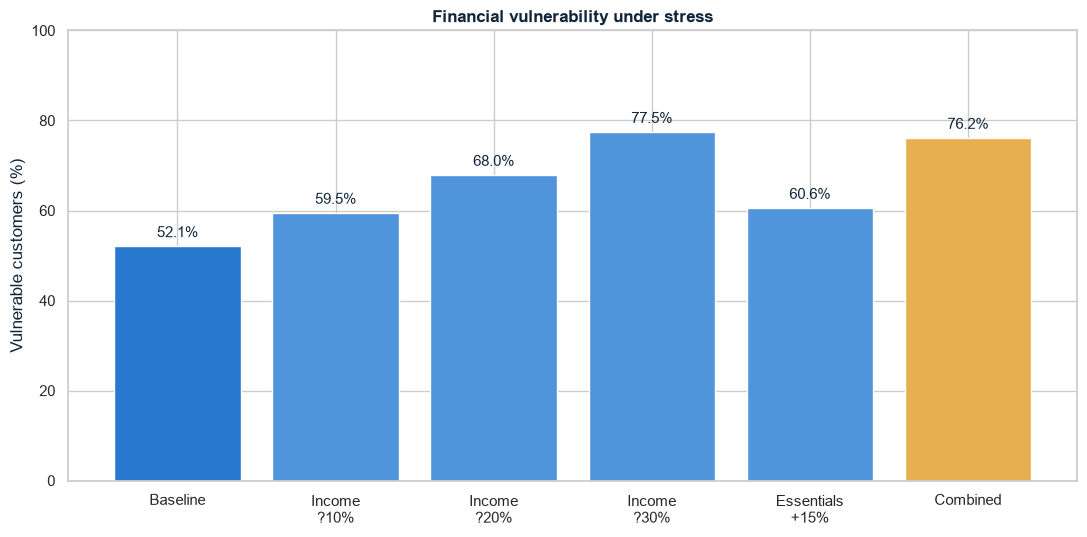

In [17]:
short_labels = ['Baseline', 'Income\n?10%', 'Income\n?20%', 'Income\n?30%', 'Essentials\n+15%', 'Combined']
plt.figure(figsize=(11, 5.5))
bars = plt.bar(short_labels, stress_summary.vulnerable_customers_pct, color=[blue] + ['#5094DB']*4 + [amber])
plt.bar_label(bars, fmt='%.1f%%', padding=4)
plt.ylim(0, 100)
plt.title('Financial vulnerability under stress')
plt.ylabel('Vulnerable customers (%)')
save_chart('stress_vulnerability.png')

In [18]:
display(Markdown(f"**Interpretation:** Vulnerability rises from {stress_summary.iloc[0].vulnerable_customers_pct:.1f}% at baseline to {stress_summary.iloc[-1].vulnerable_customers_pct:.1f}% under combined stress, a {stress_summary.iloc[-1].vulnerable_customers_pct - stress_summary.iloc[0].vulnerable_customers_pct:.1f} percentage-point increase. These are rule-based classifications, not default predictions."))

**Interpretation:** Vulnerability rises from 52.1% at baseline to 76.2% under combined stress, a 24.1 percentage-point increase. These are rule-based classifications, not default predictions.

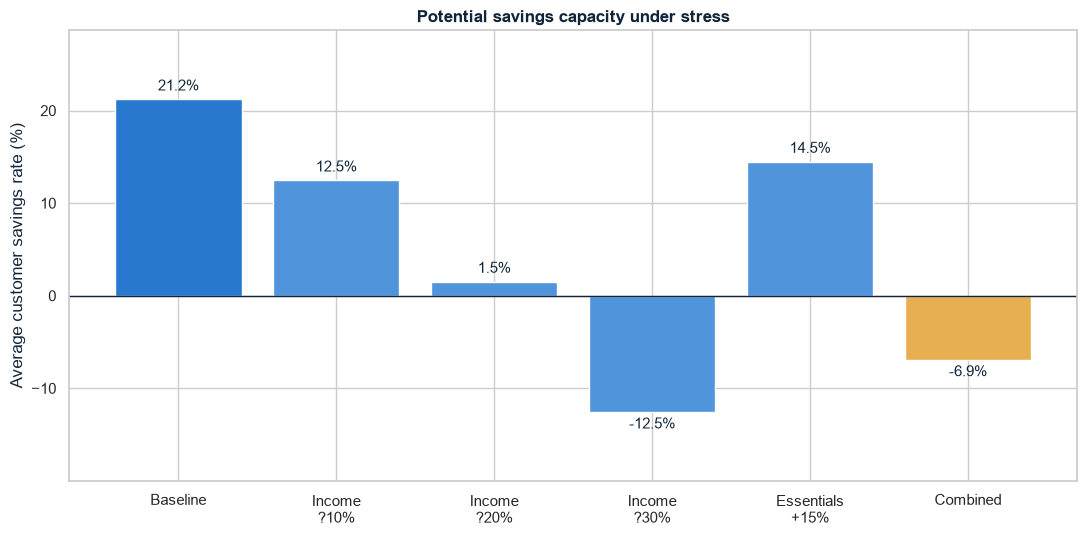

In [19]:
plt.figure(figsize=(11, 5.5))
bars = plt.bar(short_labels, stress_summary.average_savings_rate_pct, color=[blue] + ['#5094DB']*4 + [amber])
plt.bar_label(bars, fmt='%.1f%%', padding=4)
plt.axhline(0, color=navy, linewidth=1)
plt.margins(y=.22)
plt.title('Potential savings capacity under stress')
plt.ylabel('Average customer savings rate (%)')
save_chart('stress_savings.png')

In [20]:
display(Markdown(f"**Interpretation:** Average savings capacity changes from {stress_summary.iloc[0].average_savings_rate_pct:.1f}% to {stress_summary.iloc[-1].average_savings_rate_pct:.1f}% under combined stress. Customers with strictly negative surplus increase from {stress_summary.iloc[0].negative_surplus_customers:,.0f} to {stress_summary.iloc[-1].negative_surplus_customers:,.0f}. These are unweighted averages of individual ratios, not a ratio of total surplus to total income."))

**Interpretation:** Average savings capacity changes from 21.2% to -6.9% under combined stress. Customers with strictly negative surplus increase from 538 to 1,713. These are unweighted averages of individual ratios, not a ratio of total surplus to total income.

## G. Main KPIs

Show customer count, average confidence, average savings rate, average DTI, median emergency coverage, and vulnerable customers as a percentage.

Vulnerable customers (%) = Number of vulnerable customers / Total customers * 100

Each customer has equal weight in the averages.

In [21]:
kpi_summary = pd.Series({
    'Total Customers': f'{len(baseline):,}',
    'Average Financial Confidence': f'{baseline.financial_confidence_score.mean():.2f} / 100',
    'Average Savings Rate': f'{baseline.savings_rate_pct.mean():.2f}%',
    'Average DTI': f'{baseline.dti_pct.mean():.2f}%',
    'Median Emergency Coverage': f'{baseline.emergency_coverage_months.median():.2f} months',
    'Financially Vulnerable Customers': f'{baseline.financially_vulnerable.mean()*100:.2f}%'
}, name='Baseline KPI')
display(kpi_summary.to_frame())

,Baseline KPI
Total Customers,"3,000"
Average Financial Confidence,58.00 / 100
Average Savings Rate,21.22%
Average DTI,18.84%
Median Emergency Coverage,3.88 months
Financially Vulnerable Customers,52.13%


## H. Check and save results

Check the calculations and save the processed customer data and stress summary. Check all seven graphs and confirm the original CSV is unchanged.

Percentage columns use values such as 20 for 20%.

In [22]:
assert np.isfinite(baseline.select_dtypes('number')).all().all()
assert not baseline.isna().any().any()
assert (baseline[allocation_columns].sum(axis=1) == 100).all()
expected_vulnerability = ((baseline.emergency_coverage_months < 3)
    | (baseline.dti_pct >= 40) | (baseline.monthly_surplus <= 0))
assert baseline.financially_vulnerable.equals(expected_vulnerability)
assert (baseline.loc[baseline.monthly_surplus <= 0, 'potential_investable_surplus'] == 0).all()
assert np.allclose(baseline.monthly_reserve_contribution + baseline.potential_investable_surplus, baseline.monthly_surplus.clip(lower=0))
pd.testing.assert_frame_equal(baseline[expected_columns], customers)
# Boundary checks: exactly 3 months and DTI below 40 are not vulnerable if surplus is positive.
edge = customers.iloc[[0]].copy()
edge['monthly_income'] = 1000.0
edge['essential_expenses'] = 300.0
edge['discretionary_expenses'] = 100.0
edge['monthly_emi'] = 0.0
edge['liquid_savings'] = 900.0
assert not calculate_financial_metrics(edge).financially_vulnerable.iloc[0]
edge['monthly_emi'] = 400.0
edge['liquid_savings'] = 2100.0
assert calculate_financial_metrics(edge).financially_vulnerable.iloc[0]
edge['monthly_emi'] = 0.0
edge['discretionary_expenses'] = 700.0
assert calculate_financial_metrics(edge).financially_vulnerable.iloc[0]
edge['essential_expenses'] = 0.0
assert pd.isna(calculate_financial_metrics(edge).emergency_coverage_months.iloc[0])

baseline.to_csv(project_root / 'data/processed_customers.csv', index=False)
stress_summary.to_csv(project_root / 'data/stress_scenario_summary.csv', index=False)
assert hashlib.sha256(raw_path.read_bytes()).hexdigest() == raw_hash
expected_graphs = ['confidence_distribution.png', 'debt_vs_emergency.png', 'correlation_heatmap.png',
    'savings_by_region.png', 'risk_distribution.png', 'stress_vulnerability.png', 'stress_savings.png']
assert all((graphs_path / name).stat().st_size > 0 for name in expected_graphs)
assert pd.read_csv(project_root / 'data/processed_customers.csv').shape == baseline.shape
assert pd.read_csv(project_root / 'data/stress_scenario_summary.csv').shape == (6, 10)
print('All quality checks passed. Raw CSV unchanged. Seven graphs and both processed CSVs exported.')
print('Raw SHA256:', raw_hash)

All quality checks passed. Raw CSV unchanged. Seven graphs and both processed CSVs exported.
Raw SHA256: f969118a6987988ff63d5f431ce1ee973e3ec378776acb9e3dd726271da8007b
